# Value - the building block of a Neuron

In [211]:
import math

In [212]:
from graphviz import Digraph


def trace(root):
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges


def draw_dot(root, format="svg", rankdir="LR"):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ["LR", "TB"]
    nodes, edges = trace(root)
    dot = Digraph(
        format=format, graph_attr={"rankdir": rankdir}
    )  # , node_attr={'rankdir': 'TB'})

    for n in nodes:
        dot.node(
            name=str(id(n)),
            label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad),
            shape="record",
        )
        if n._op:
            dot.node(name=str(id(n)) + n._op, label=n._op)
            dot.edge(str(id(n)) + n._op, str(id(n)))

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [213]:
def tests():
    value = 2.0
    value_label = "V"
    value_op = "op"
    a = Value(2.0)

    # init
    assert a.data == value
    assert a.label == ""
    a.label = value_label
    assert a.label == value_label
    a._op = value_op
    assert a._op == value_op
    a._prev = ()
    assert a._prev == ()
    a._prev = (a, a)
    assert isinstance(a._prev, tuple)
    assert a._prev == (a, a)
    assert repr(a) == f"Value(data={value})"

    # multiplication
    o = a * a  # can multiply 2 Value objects
    assert o.data == value * value
    o = a * 3  # can multiply a Value object to an int or float
    assert o.data == value * 3
    assert isinstance(o.data, float)
    o = a * 3.0
    assert o.data == value * 3.0
    assert isinstance(o.data, float)
    o = 3 * a  # can multiply in or float to Value object
    o = 3 * a
    assert o.data == value * 3
    assert isinstance(o.data, float)
    o = 3.0 * a
    assert o.data == value * 3.0
    assert isinstance(o.data, float)

    # addition
    o = a + a  # can add two Value objects
    assert o.data == value + value
    o = a + 3  # can add Value object to an int or float
    assert o.data == value + 3
    o = a + 3.0
    assert o.data == value + 3.0
    assert isinstance(o.data, float)
    o = 3 + a  # can add an int or float to a Value object
    assert o.data == value + 3
    assert isinstance(o.data, float)
    o = 3.0 + a
    assert o.data == value + 3.0
    assert isinstance(o.data, float)

    # tahn
    o = a.tahn()
    assert o.data == math.tanh(a.data)


tests()

In [214]:
class Value:
    """Value is the single scalar node in a computational graph."""

    def __init__(self, data, _children=(), _op="", label=""):
        self.data = data
        self.grad = 0.0
        self.label = label
        self._prev = _children
        self._op = _op

    def __repr__(self):
        return f"Value(data={self.data})"

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        return out

    def __rmul__(self, other):  # other * self
        return self * other

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), _op="+")
        return out

    def __radd__(self, other):  # other + self
        return self + other

    def tahn(self):
        # Hyperbolic tangent definition: (exp(2*x) - 1) / (exp(2*x) + 1)
        t = (math.exp(2 * self.data) - 1) / (math.exp(2 * self.data) + 1)
        out = Value(t, (self,), "tahn")
        return out


tests()

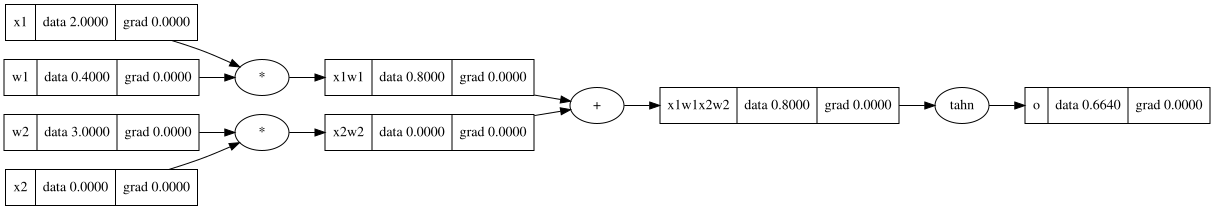

In [215]:
# Building the Value

x1 = Value(2.0, label="x1")
w1 = Value(0.4, label="w1")
x2 = Value(0.0, label="x2")
w2 = Value(3.0, label="w2")

x1w1 = x1 * w1
x1w1.label = "x1w1"
x2w2 = x2 * w2
x2w2.label = "x2w2"

x1w1x2w2 = x1w1 + x2w2
x1w1x2w2.label = "x1w1x2w2"

o = x1w1x2w2.tahn()
o.label = "o"

draw_dot(o)